In [1]:
import numpy as np
from scipy.io import loadmat
import ipywidgets as widgets
from scipy.signal import resample
import os 

import matplotlib.pyplot as plt
from ipywidgets import IntRangeSlider, VBox, HBox, Output,Label
from IPython.display import display, Audio
from ipyfilechooser import FileChooser
%config InlineBackend.figure_format = 'svg'

from scipy import signal as sig
import matplotlib.pyplot as plt
import Funciones as Funciones
from NNMF_GIF import NNMF_GIF 
from pathlib import Path
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import  clear_output
def procesar_senales(idx_ini, idx_fin, fs_original, MBK, OVV, UG, fs_target=8000, ventana_ms=50):
    """
    Recorta las señales entre idx_ini e idx_fin, las resamplea a fs_target
    y las divide en ventanas de ventana_ms milisegundos.
    
    Parámetros:
    -----------
    idx_ini : int
        Índice inicial de recorte
    idx_fin : int
        Índice final de recorte
    fs_original : int
        Frecuencia de muestreo original de las señales
    MBK, ACC, OVV, EGG : np.ndarray
        Señales originales
    fs_target : int, opcional
        Frecuencia de muestreo destino (default=8000 Hz)
    ventana_ms : int, opcional
        Duración de cada ventana en milisegundos (default=50 ms)
    
    Retorna:
    --------
    dict con las señales divididas en ventanas:
        {
          'MBK': [ventana1, ventana2, ...],
          'ACC': [...],
          'OVV': [...],
          'EGG': [...]
        }
    """
    
    # Recorte
    MBK_cut = MBK[idx_ini:idx_fin]
    OVV_cut = OVV[idx_ini:idx_fin]
    UG_cut = UG[idx_ini:idx_fin]
    
    # Número de muestras en la señal recortada
    n_samples = idx_fin - idx_ini
    
    # Número de muestras después del resample
    n_samples_resampled = int(n_samples * fs_target / fs_original)
    
    # Resampleo
    MBK_res = resample(MBK_cut, n_samples_resampled)
    OVV_res = resample(OVV_cut, n_samples_resampled)
    UG_res = resample(UG_cut, n_samples_resampled)
    
    # Tamaño de ventana en muestras
    ventana_samples = int(fs_target * ventana_ms / 1000)
    
    def dividir_en_ventanas(signal, ventana_samples):
        n = len(signal)
        return [signal[i:i+ventana_samples] for i in range(0, n, ventana_samples) if len(signal[i:i+ventana_samples]) == ventana_samples]
    
    # División en ventanas
    resultado = {
        'MBK': dividir_en_ventanas(MBK_res, ventana_samples),
        'OVV': dividir_en_ventanas(OVV_res, ventana_samples),
        'UG': dividir_en_ventanas(UG_res, ventana_samples)
    }
    
    return resultado

def guardar_ventanas(ventanas_dict, ruta, nombre_base):
    """
    Guarda cada ventana como archivo .txt con columnas MBK, ACC, OVV, EGG.
    
    Parámetros:
    -----------
    ventanas_dict : dict
        Diccionario con listas de ventanas, como el que devuelve procesar_senales().
        Ejemplo: {'MBK': [...], 'ACC': [...], 'OVV': [...], 'EGG': [...]}
    ruta : str
        Carpeta donde se guardarán los archivos
    nombre_base : str
        Nombre base de los archivos. Se le adjunta el índice de la ventana.
        Ejemplo: 'ventana' -> ventana_1.txt, ventana_2.txt, ...
    """
    os.makedirs(ruta, exist_ok=True)
    
    n_ventanas = len(ventanas_dict['MBK'])
    
    for i in range(n_ventanas):
        mbk_win = ventanas_dict['MBK'][i]
        ovv_win = ventanas_dict['OVV'][i]
        egg_win = ventanas_dict['UG'][i]
        
        matriz = np.column_stack([mbk_win, ovv_win, egg_win])
        
        filename = os.path.join(ruta, f"{nombre_base}_{i+1}.txt")
        
        np.savetxt(filename, matriz, fmt="%.6f", delimiter="\t",
                   header="MBK\t\tOVV\tUG", comments='')

#%matplotlib widget

In [2]:
#ruta = r"G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Repositorio AC3E\Controles\FN001\R02 - Calibrated Gestures\vowels.mat"
FC = FileChooser('OVV sintetica')
FC.layout = widgets.Layout(width='1000px')
display(FC)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\OVV sintetica', filename='', title='', show_hidden=F…

In [5]:
mat_contents = loadmat(FC.selected, squeeze_me=True)
fs = 48000
min_range = 600
MBK = mat_contents["datos"]["s"]
MBK_ = (np.array(MBK)/ np.max(np.abs(MBK))).astype(np.float32)

OVV = mat_contents["datos"]["ovv"][()]
UG  = mat_contents["datos"]["ug"][()]

ValueError: Unknown mat file type, version 46, 55

NameError: name 'MBK_' is not defined

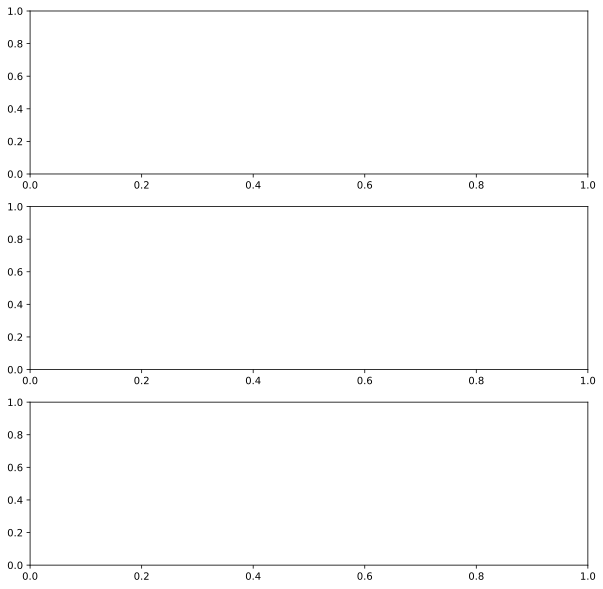

In [6]:
fig,(ax1,ax2,ax3) = plt.subplots(3,1,figsize=(10,10))
inicio = 18000
fin = 24000
ax1.plot(MBK_[inicio:fin])
ax2.plot(OVV[inicio:fin])
ax3.plot(UG[inicio:fin]);

In [ ]:
ventanas = procesar_senales(18000, 24000, fs, MBK_, OVV, UG)
guardar_ventanas(ventanas, ruta="OVV sintetica", nombre_base="Vocal_A__")
#print(f"Número de ventanas: {len(ventanas['MBK'])}")
#print(f"Tamaño de cada ventana: {len(ventanas['MBK'][0])} muestras")

In [7]:
FC = FileChooser('OVV sintetica')
FC.layout = widgets.Layout(width='1000px')
display(FC)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\OVV sintetica', filename='', title='', show_hidden=F…

In [9]:
archivo = Path(FC.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)
#datos = datos[:,:-1]
linewidth = 2
alfa_grid = 0.3
fs_r = 8000
to = 0
tf = 50
tiempos       = np.arange(to,tf,1000/fs_r)
color_notch = 'red'
color_lpc  = 'orange'
color_flujo = 'k'
color1 = 'red'
color2 = 'blue'

señal_OVV_  = datos[:, 1] - np.mean(datos[:, 1])


#---------------- Filtro pasa bajos en 1,1 kHz -------------------------------------------------------------------------
orden = 10 
ripple = 0.1
fc     = 1100
fs_r = 8000
b,a   = sig.cheby1(orden,ripple,fc,'lowpass',fs=fs_r)
señal_OVV_f = sig.filtfilt(b,a,señal_OVV_)
#---------------- Integro para sacar el efecto derivador que tiene la señal  ------------------------------------------
#alfa = 0.96
# Filtro según el paper de BROOKE
'''
alfa= np.exp(-2*np.pi*50/fs_r)
num = [1,-1]
den = [1,-2*alfa,alfa**2]
flujo_OVV_original =  sig.lfilter(num,den,señal_OVV_f)
maximo = max(abs(flujo_OVV_original))
flujo_OVV_original = [val/maximo for val in flujo_OVV_original]
'''
flujo_OVV_original=señal_OVV_f/max(abs(señal_OVV_f))
fft_flujo_OVV_original, frec_flujo_OVV_original= Funciones.FFT(flujo_OVV_original, fs_r)


#---------------- Aplico el Notch  -----------------------------------------------------------------------------------

flujo_ovv, FF,error,b_notch,a_notch = Funciones.INF(flujo_OVV_original)
maximo = max(abs(flujo_ovv))
flujo_ovv = [val/maximo for val in flujo_ovv]
#------------------------------------------------------------------------------------------------------------------------------
Q_widget = widgets.FloatText(
    value=10,
    min=0.001,
    max=1000.00,
    step=0.1,
    description='Q =',
    disabled=False,
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
slider = widgets.IntSlider(
    value=FF,
    min=200,
    max=1000,
    step=1,
    description='Frecuencia [Hz]:',
    style={'description_width':'initial'},
)
reset_button = widgets.Button(
    description="Defecto",
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
guardar_button = widgets.Button(
    description="Guardar"
)
def reset_slider(b):
    slider.value = FF

reset_button.on_click(reset_slider)
def guardar(b):
    with open(archivo, 'r') as f:
        cabecera = f.readline().strip()
    if datos.shape[1] > 3:
        datos[:, 3] = flujo_ovv
        frec_ = np.full(len(flujo_ovv), np.nan)
        frec_[0] = slider.value
        datos[:, 4] = frec_
        Q_ = np.full(len(flujo_ovv), np.nan)
        Q_[0] = Q_widget.value
        datos[:, 5] = Q_
        np.savetxt(
            archivo,
            datos,
            fmt="%.6f",
            delimiter='\t',
            header=cabecera,
            comments=''
        )
    else:
        frec_ = np.full(len(flujo_ovv), np.nan)
        frec_[0] = slider.value
        Q_ = np.full(len(flujo_ovv), np.nan)
        Q_[0] = Q_widget.value
        datos_nuevos = np.column_stack((datos, flujo_ovv,frec_,Q_))
        cabecera_nueva = cabecera + '\tFlujo OVV' + '\tFrecuencia_Notch' + '\tQ Notch'
        np.savetxt(
            archivo,
            datos_nuevos,
            fmt="%.6f",
            delimiter='\t',
            header=cabecera_nueva,
            comments=''
        )

reset_button.on_click(reset_slider)
guardar_button.on_click(guardar)
label = widgets.Label(value=f"Ancho de banda= {round(FF/Q_widget.value,0)} [Hz]")
def actualizar_label(change):
    label.value = f"Ancho de banda= {round(FF/Q_widget.value,0)} [Hz]"
slider.observe(actualizar_label, names='value')
Q_widget.observe(actualizar_label, names='value')
 
def graficar(frec_slider,Q_):
    clear_output(wait=True)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [2, 1]})
    fig.subplots_adjust(hspace=0.25)
    ax1 = ax[0]
    ax2 = ax[1]
    ax1.clear()
    ax2.clear()
    b, a = sig.iirnotch(w0=frec_slider,fs=fs_r, Q=Q_)
    w_notch, h_notch = sig.freqz(a,b,fs=fs_r,worN=4096)
    global flujo_ovv
    flujo_ovv = sig.lfilter(b, a, flujo_OVV_original)
    maximo = max(abs(flujo_ovv))
    flujo_ovv = [val/maximo for val in flujo_ovv]
    ax1.plot(tiempos, flujo_OVV_original, color='k', label=r'$u_{g}(t)$',linewidth=linewidth)
    ax1.plot(tiempos, flujo_ovv, color=color_notch, label=r'$u_{g}(t)$ - Notch',linewidth=linewidth)
    ax1.legend(loc='upper right')
    ax1.set_xlabel('Tiempo [ms]')
    ax1.set_title(nombre_archivo,pad=20)
    ax1.set_xlim([10,40])
    ax2.plot(frec_flujo_OVV_original, 10*np.log10(abs(fft_flujo_OVV_original)), color=color_flujo, label=r'$u_{g}(t)$',linewidth=linewidth)
    ax2.plot(w_notch, 10*np.log10(abs(h_notch)), color=color_notch,label='Notch',linewidth=linewidth)
    ax2.legend(loc='center right')
    ax2.set_ylim([-10,20]);
    plt.show()
out = widgets.interactive_output(graficar, {'frec_slider': slider,'Q_':Q_widget})
ui = widgets.HBox([slider,reset_button, Q_widget,label, guardar_button]);
display(widgets.VBox([ui,out]));


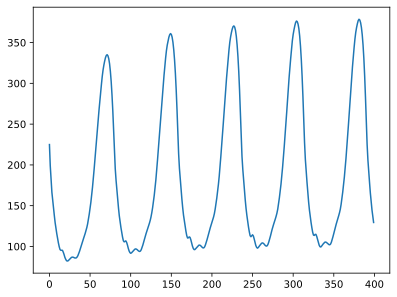

In [ ]:
plt.plot(datos[:, 2])